In [5]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from pre_processing import pre_process, json_decode


sns.set_palette("hsv_r")

# This affects things like the size of the labels, lines, and other elements of the plot, but not the overall style. 
# The base context is “notebook”, and the other contexts are “paper”, “talk”, and “poster”, which are version of 
# the notebook parameters scaled by .8, 1.3, and 1.6, respectively.
sns.set_context("talk")

%config Inline.figure_format = 'retina'
%matplotlib inline

## Read in Data 

In [6]:
# File paths for each experimental condition (can contain multiple subjects/files) 
file_paths_baseline = [
    "../data/csv_files/06_baseline.csv", 
    "../data/csv_files/07_baseline.csv", 
    "../data/csv_files/08_baseline.csv", 
    "../data/csv_files/09_baseline.csv"
]

file_paths_repulse = [
    "../data/csv_files/06_repulse.csv", 
    "../data/csv_files/07_repulse.csv", 
    "../data/csv_files/08_repulse.csv", 
    "../data/csv_files/09_repulse.csv"
]

file_paths_udl = [
    "../data/csv_files/06_udl.csv", 
    "../data/csv_files/07_udl.csv", 
    "../data/csv_files/08_udl.csv", 
    "../data/csv_files/09_udl.csv"
]

# Subject identifiers corresponding to the datasets
# Actual participants have randomly generated KinArm IDs
subject_list = ["105283198",    
                "263471501", 
                "145349743", 
                "23426115"]    

# Load CSV files & label condition
df_baseline_raw = pre_process(file_paths_baseline, subject_list)
df_baseline_raw['phase'] = 'baseline'

df_repulse_raw = pre_process(file_paths_repulse, subject_list)
df_repulse_raw['phase'] = 'repulse'

df_udl_raw = pre_process(file_paths_udl, subject_list)
df_udl_raw['phase'] = 'udl'

## Define Functions 

In [7]:
# function to unpack repeated target value from series
# WE HAVENT USE THIS ONE YET.. copied from Jeremy's analysis script
def find_rep(group):
    vals = group['Repeated_Target'].iloc[0]
    return vals[1:4]   


def N_finder(group, N_minus_targ):
    
    # Find trials where N-1 had the specified target
    N_trial_num = (group.loc[group['target_angle'] == N_minus_targ,'TN'] + 1)

    # Return trial N
    N_df = group.loc[group['TN'].isin(N_trial_num)]
    return N_df


def calculate_se_index(df, y_col):
    """
    calculate the sequential effect (SE) index per participant 
    POSITIVE SE Index = attractive bias (UDL)
    NEGATIVE SE Index = repulsive bias (REPULSE)

    parameters: 
    df : DataFrame; data to calculate SE index from
    y_col : str; column containing corrected bias

    output: 
    df with the SE index per participant 
    """
    negative_mean = df.loc[df["target_angle_diff"] < 0].groupby("SN")[y_col].mean()
    positive_mean = df.loc[df["target_angle_diff"] > 0].groupby("SN")[y_col].mean()

    return negative_mean - positive_mean 

def circ_dist(ang1, ang2):

    ang1rad = np.deg2rad(ang1)
    ang2rad = np.deg2rad(ang2)
    ang_dist = np.rad2deg(np.arctan2(np.sin(ang1rad), np.cos(ang2rad)))

    return ang_dist


## should probably create a function that determines the repeated target and changes all the targets to be centred around ZERO 

## Repulse

In [8]:
###starting with the repulsive phase#####

df_repulse_raw['TN'] = df_repulse_raw.groupby('SN').cumcount()

central_target_2 = {
    1: 150,
    2: 60,
    3: 120,
    4: 60
}

# Shift target angles so each participant's central target = 0°
for sn, central_angle in central_target_2.items():
    mask = df_repulse_raw["SN"] == sn
    TA_rad_shift = df_repulse_raw.loc[mask, "target_angle"] - central_angle
    df_repulse_raw.loc[mask, "target_angle"] = circ_dist(TA_rad_shift, TA_rad_shift).round()

# Get target location difference (delta target angle) values
df_repulse_raw['target_angle_diff'] = pd.Series(pd.NA, index=df_repulse_raw.index, dtype='Float64')
RadTAN1diff_repulse = np.deg2rad(df_repulse_raw.groupby('SN')['target_angle'].diff(periods=1))
df_repulse_raw['target_angle_diff'] = np.rad2deg(np.arctan2(np.sin(RadTAN1diff_repulse), np.cos(RadTAN1diff_repulse)))
df_repulse_raw['target_angle_diff'] = df_repulse_raw['target_angle_diff'].round().astype('Int64')


# Calculate bias for each participant (for REPULSE), which is used for bias correction in the UDL condition
bias_subset_repulse_raw = (
    df_repulse_raw.loc[(df_repulse_raw['TN'] >= 99) & (df_repulse_raw['TN'] < 700) & 
    (df_repulse_raw['reach_feedback'] == 'good reach') & 
    (df_repulse_raw['theta_pv'].abs() < 60)]
    .groupby(['SN', 'target_angle'], as_index=False)['theta_pv']
    .mean()
    .rename(columns={'theta_pv': 'bias_repulse'})
)

df_repulse_raw = df_repulse_raw.merge(bias_subset_repulse_raw, on=['SN', 'target_angle'], how='left')

# Correct for target-level reach biases (for REPULSE) by subtraction of mean hand angle to a target
RadCorrDiff = np.deg2rad(df_repulse_raw['theta_pv'] - df_repulse_raw['bias_repulse'])
df_repulse_raw['corrected_bias_repulse'] = np.rad2deg(np.arctan2(np.sin(RadCorrDiff), np.cos(RadCorrDiff)))


Text(0, 0.5, 'Corrected Bias')

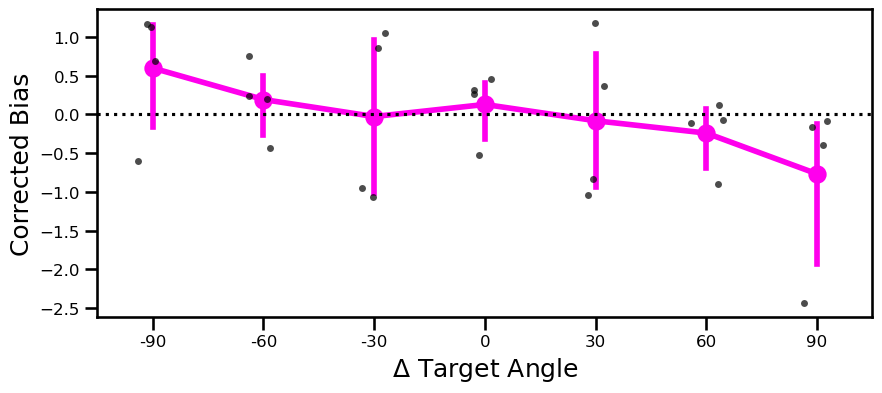

In [9]:
############## PLOT #########################

###### THE PROBLEM IS RIGHT HERE ############ 

repulse_mask = (
    (df_repulse_raw['reach_feedback'] == 'good reach') &  
    (df_repulse_raw['rt'] > 0.5) &  
    (np.abs(df_repulse_raw['theta_pv']) < 60) &
    (df_repulse_raw["target_angle_diff"].abs() <= 90)
)

df_repulse_clean = df_repulse_raw.loc[repulse_mask].copy()

df_repulse_subset = (
    df_repulse_clean
    # df_repulse_raw
    .groupby(['SN', 'target_angle_diff'])['corrected_bias_repulse' ]
    .mean()
    .reset_index()
)

fig, ax = plt.subplots(figsize=(10,4))
sns.pointplot(
    data=df_repulse_subset,
    x='target_angle_diff',
    y='corrected_bias_repulse',
    estimator='mean',
    errorbar=('ci',95),
    ax=ax
)

sns.stripplot(
    data=df_repulse_subset,
    x='target_angle_diff',
    y='corrected_bias_repulse',
    color='black',
    alpha=0.7,
    jitter=0.15,
    size=5,
    ax=ax
)
ax.axhline(0, color='black', linestyle=':')
ax.tick_params(axis='x', labelsize=12)
ax.tick_params(axis='y', labelsize=12)
plt.xlabel(r'$\Delta$ Target Angle')
plt.ylabel('Corrected Bias')

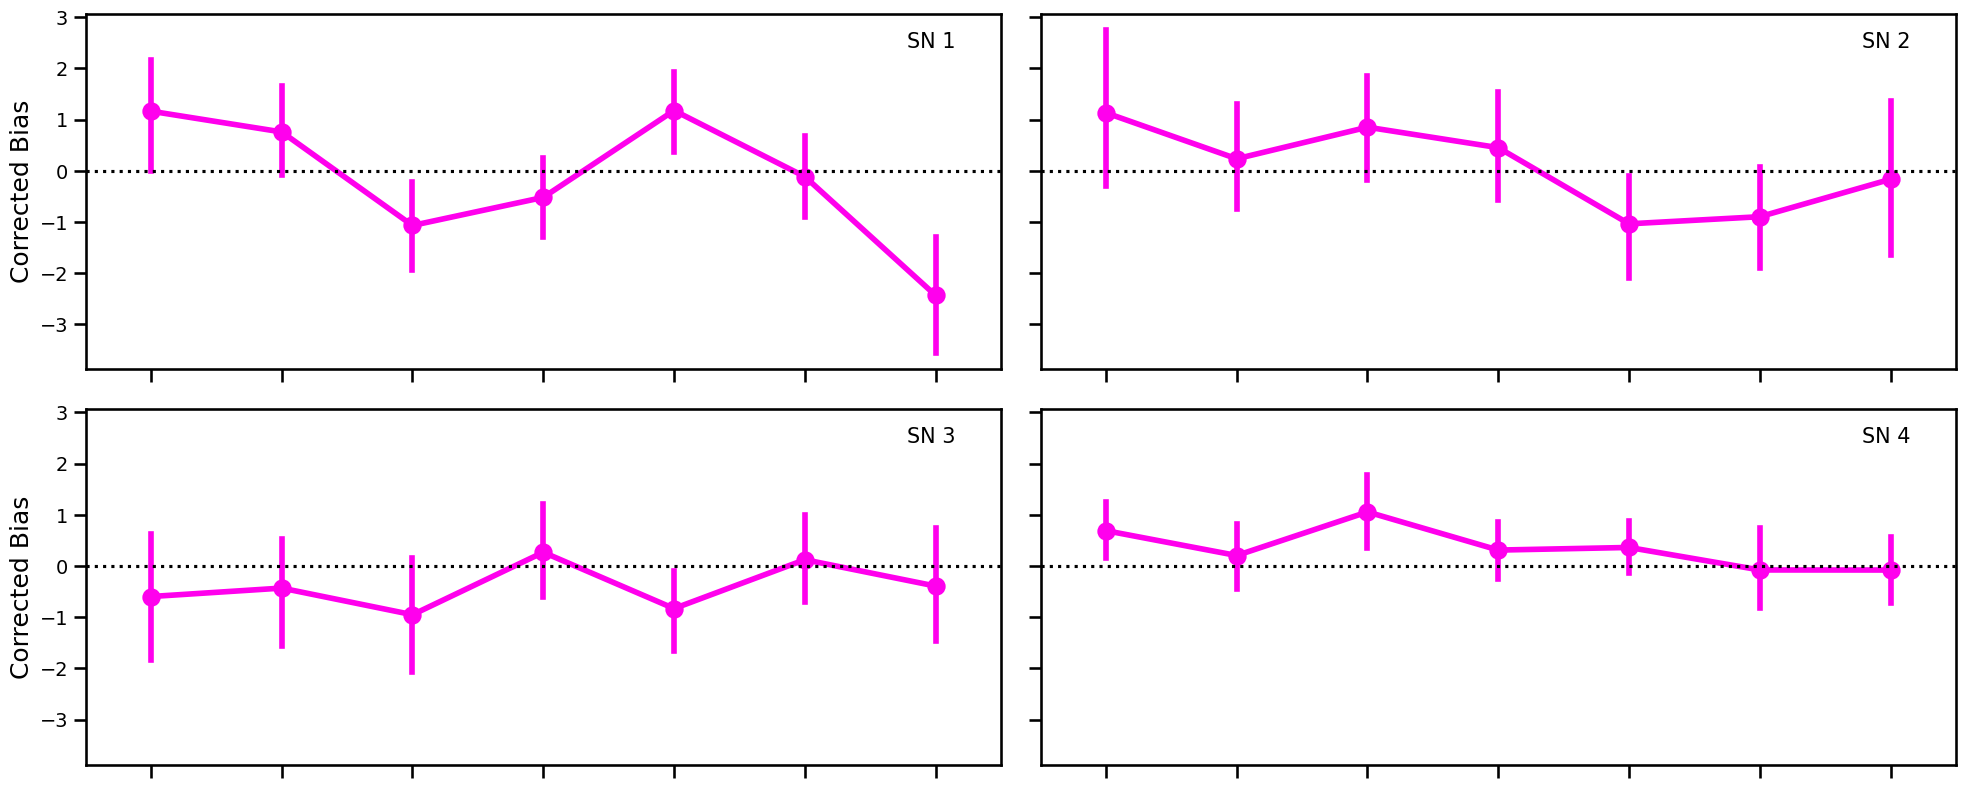

In [10]:
participants = sorted(df_repulse_clean['SN'].unique())

fig, axes = plt.subplots(3, 2, figsize=(20, 12), sharex=True, sharey=True)
axes = axes.flatten()

for ax, subject_num in zip(axes, participants):

    sns.pointplot(
        data=df_repulse_clean[df_repulse_clean['SN'] == subject_num],
        x='target_angle_diff',
        y='corrected_bias_repulse',
        estimator='mean',
        errorbar=('ci', 95),
        ax=ax
    )

    ax.axhline(0, color='black', linestyle=':')
    ax.tick_params(axis='x', labelsize=14)
    ax.tick_params(axis='y', labelsize=14)

    ax.set_ylabel('Corrected Bias')
    ax.set_xlabel('')

    ax.text(
        0.95, 0.95,
        f'SN {subject_num}',
        transform=ax.transAxes,
        ha='right',
        va='top',
        fontsize=15
    )

# remove unused subplot(s)
for ax in axes[len(participants):]:
    ax.remove()

plt.tight_layout()
plt.show()

## UDL

In [11]:
df_udl_raw['TN'] = df_udl_raw.groupby('SN').cumcount()

# Shift target angles so each participant's central target = 0°
for sn, central_angle in central_target_2.items():
    mask = df_udl_raw["SN"] == sn
    TA_rad_shift = df_udl_raw.loc[mask, "target_angle"] - central_angle
    df_udl_raw.loc[mask, "target_angle"] = circ_dist(TA_rad_shift, TA_rad_shift).round()


# Get target location difference (delta target angle) values
df_udl_raw['target_angle_diff'] = pd.Series(pd.NA, index=df_udl_raw.index, dtype='Float64')
RadTAN1diff_udl = np.deg2rad(df_udl_raw.groupby('SN')['target_angle'].diff(periods=1))
df_udl_raw['target_angle_diff'] = np.rad2deg(np.arctan2(np.sin(RadTAN1diff_udl), np.cos(RadTAN1diff_udl)))
df_udl_raw['target_angle_diff'] = df_udl_raw['target_angle_diff'].round().astype('Int64')


# Calculate bias for each participant (for UDL), which is used for bias correction in the UDL condition
bias_subset_udl_raw = (
    df_udl_raw.loc[(df_udl_raw['TN'] >= 70) &
                   (df_udl_raw['TN'] < 139) &
                   (df_udl_raw['reach_feedback'] == 'good reach') &
                   (df_udl_raw['theta_pv'].abs() < 60)]
                   .groupby(['SN', 'target_angle'], as_index=False)['theta_pv']
                   .mean()
                   .rename(columns={'theta_pv': 'bias_udl'})
                   )


df_udl_raw = df_udl_raw.merge(bias_subset_udl_raw,on=['SN', 'target_angle'],how='left')
RadCorrDiff = np.deg2rad(df_udl_raw['theta_pv'] - df_udl_raw['bias_udl'])
df_udl_raw['corrected_bias_udl'] = np.rad2deg(np.arctan2(np.sin(RadCorrDiff), np.cos(RadCorrDiff)))

In [12]:
mask_udl = (
    (df_udl_raw['TN'] >= 1) &
    (df_udl_raw['TN'] < 1005) &
    (df_udl_raw['reach_feedback'] == 'good reach') &
    (df_udl_raw['rt'] > 0.5) &
    (df_udl_raw['theta_pv'].abs() < 60) &
    (df_udl_raw['target_angle_diff'].abs() <= 90)
)

df_udl = df_udl_raw.loc[mask_udl].copy()

df_udl_constrained = (
    df_udl
    .groupby('SN', group_keys=False)
    .apply(N_finder, N_minus_targ=0)
    .reset_index(drop=True)
    .copy()
)

df_udl_constrained = df_udl_constrained.loc[df_udl_constrained['probe'] == 1].copy()

subject_means_udl = (df_udl_constrained.groupby(['SN', 'target_angle_diff'], as_index=False)['theta_pv'].mean())

/var/folders/g6/bw3kklz96vl7dn2xz_xpz9440000gn/T/ipykernel_73609/3688996596.py:15: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(N_finder, N_minus_targ=0)


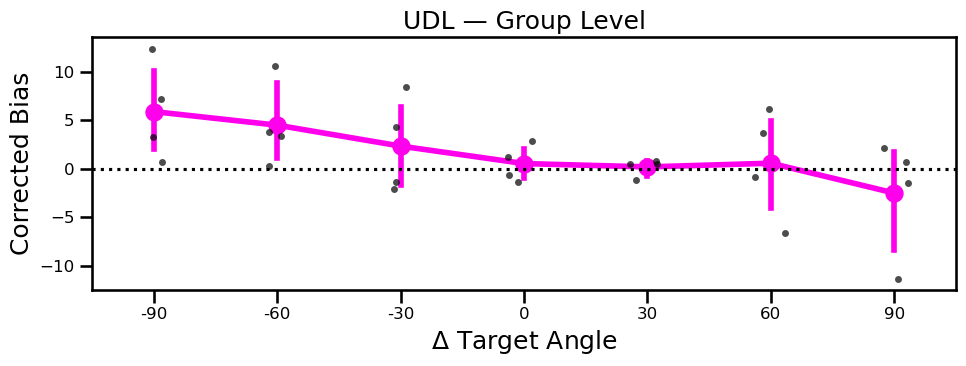

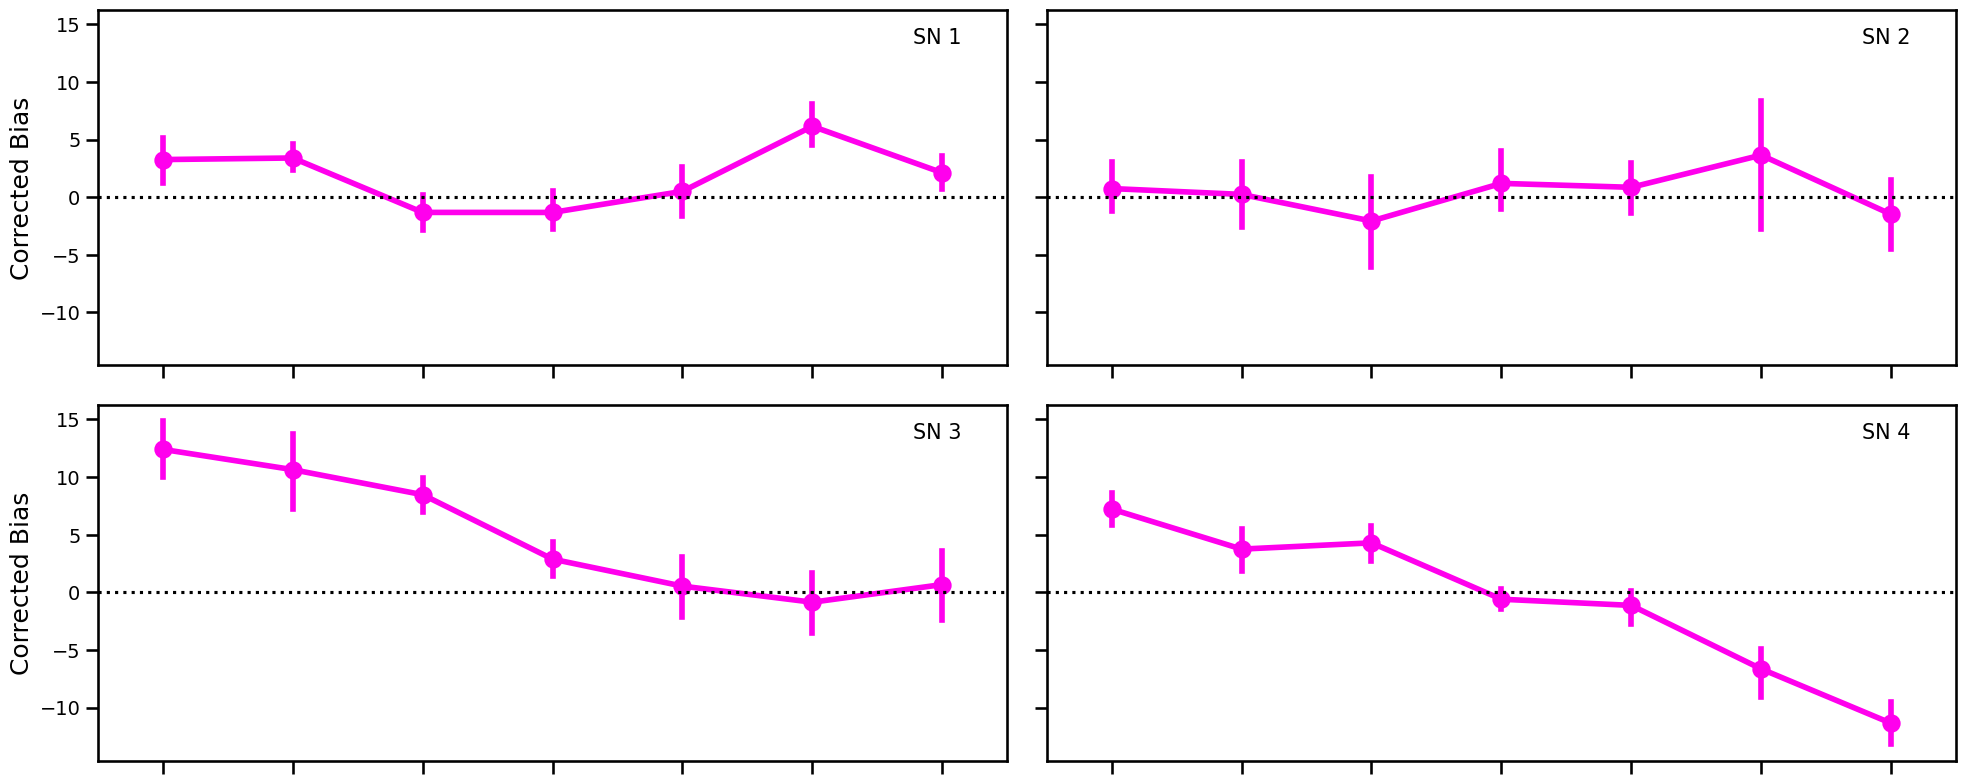

In [13]:
# GROUP-LEVEL PLOT
fig, ax = plt.subplots(figsize=(10, 4))

sns.pointplot(
    data=subject_means_udl,
    x='target_angle_diff',
    y='theta_pv',
    estimator='mean',
    errorbar=('ci', 95),
    ax=ax
)

sns.stripplot(
    data=subject_means_udl,
    x='target_angle_diff',
    y='theta_pv',
    color='black',
    alpha=0.7,
    jitter=0.15,
    size=5,
    ax=ax
)

ax.axhline(0, color='black', linestyle=':')
ax.tick_params(axis='x', labelsize=12)
ax.tick_params(axis='y', labelsize=12)
plt.xlabel(r'$\Delta$ Target Angle')
plt.ylabel('Corrected Bias')
plt.title('UDL — Group Level')
plt.tight_layout()
plt.show()


# BY PARTICIPANT
participants = sorted(df_udl_constrained['SN'].unique())

fig, axes = plt.subplots(3, 2, figsize=(20, 12), sharex=True, sharey=True)
axes = axes.flatten()

for ax, subject_num in zip(axes, participants):

    sns.pointplot(
        data=df_udl_constrained[df_udl_constrained['SN'] == subject_num],
        x='target_angle_diff',
        y='theta_pv',
        estimator='mean',
        errorbar=('ci', 95),
        ax=ax
    )

    ax.axhline(0, color='black', linestyle=':')
    ax.tick_params(axis='x', labelsize=14)
    ax.tick_params(axis='y', labelsize=14)

    ax.set_ylabel('Corrected Bias')
    ax.set_xlabel('')

    ax.text(
        0.95, 0.95,
        f'SN {subject_num}',
        transform=ax.transAxes,
        ha='right',
        va='top',
        fontsize=15
    )

# remove unused subplot(s)
for ax in axes[len(participants):]:
    ax.remove()

plt.tight_layout()
plt.show()

## Individual data frames

In [14]:
###starting with the repulsive phase#####

df_repulse_raw['TN'] = df_repulse_raw.groupby('SN').cumcount()

central_target_2 = {
    1: 150,
    2: 60,
    3: 120,
    4: 60
}

# Shift target angles so each participant's central target = 0°
for sn, central_angle in central_target_2.items():
    mask = df_repulse_raw["SN"] == sn
    TA_rad_shift = df_repulse_raw.loc[mask, "target_angle"] - central_angle
    df_repulse_raw.loc[mask, "target_angle"] = circ_dist(TA_rad_shift, TA_rad_shift).round()

# Calculate bias for each participant (for REPULSE), which is used for bias correction in the UDL condition
bias_subset_repulse_raw = (
    df_repulse_raw.loc[(df_repulse_raw['TN'] >= 99) & (df_repulse_raw['TN'] < 700) & 
    (df_repulse_raw['reach_feedback'] == 'good reach') & 
    (df_repulse_raw['theta_pv'].abs() < 60)]
    .groupby(['SN', 'target_angle'], as_index=False)['theta_pv']
    .mean()
    .rename(columns={'theta_pv': 'bias_repulse'})
)

df_repulse_raw = df_repulse_raw.merge(bias_subset_repulse_raw, on=['SN', 'target_angle'], how='left')

# Correct for target-level reach biases (for REPULSE) by subtraction of mean hand angle to a target
RadCorrDiff = np.deg2rad(df_repulse_raw['theta_pv'] - df_repulse_raw['bias_repulse'])
df_repulse_raw['corrected_bias_repulse'] = np.rad2deg(np.arctan2(np.sin(RadCorrDiff), np.cos(RadCorrDiff)))

# Get target location difference (delta target angle) values
df_repulse_raw['target_angle_diff'] = pd.Series(pd.NA, index=df.index, dtype='Float64')
RadTAN1diff_repulse = np.deg2rad(df_repulse_raw.groupby('SN')['target_angle'].diff(periods=1))
df_repulse_raw['target_angle_diff'] = np.rad2deg(np.arctan2(np.sin(RadTAN1diff_repulse), np.cos(RadTAN1diff_repulse)))
df_repulse_raw['target_angle_diff'] = df_repulse_raw['target_angle_diff'].round().astype('Int64')


######################################################################################################################################################
######################################################################################################################################################

###and repeat for UDL phase#####

df_udl_raw['TN'] = df_udl_raw.groupby('SN').cumcount()

# Shift target angles so each participant's central target = 0°
for sn, central_angle in central_target_2.items():
    mask = df_udl_raw["SN"] == sn
    TA_rad_shift = df_udl_raw.loc[mask, "target_angle"] - central_angle
    df_udl_raw.loc[mask, "target_angle"] = circ_dist(TA_rad_shift, TA_rad_shift).round()
    #df_udl_raw.loc[mask, "target_angle"] = TA_rad_shift + 120


# Calculate bias for each participant (for UDL), which is used for bias correction in the UDL condition
bias_subset_df_udl = (
   df_udl_raw.loc[(df_udl_raw['TN'] >= 0) & (df_udl_raw['TN'] < 67) & 
   (df_udl_raw['reach_feedback'] == 'good reach') & 
   (df_udl_raw['theta_pv'].abs() < 60)]
   .groupby(['SN', 'target_angle'], as_index=False)['theta_pv']
   .mean()
   .rename(columns={'theta_pv': 'bias_udl'})
)

# bias_subset_df_udl = (
#     df_repulse_raw.loc[(df_repulse_raw['TN'] >= 99) & (df_repulse_raw['TN'] < 700) & 
#     (df_repulse_raw['reach_feedback'] == 'good reach') & 
#     (df_repulse_raw['theta_pv'].abs() < 60)]
#     .groupby(['SN', 'target_angle'], as_index=False)['theta_pv']
#     .mean()
#     .rename(columns={'theta_pv': 'bias_repulse_for_udl'})
# )

df_udl_raw = df_udl_raw.merge(bias_subset_df_udl, on=['SN', 'target_angle'], how='left')

# Correct for target-level reach biases (for UDL) by subtraction of mean hand angle to a target
RadCorrDiff = np.deg2rad(df_udl_raw['theta_pv'] - df_udl_raw['bias_udl'])
df_udl_raw['corrected_bias_udl'] = np.rad2deg(np.arctan2(np.sin(RadCorrDiff), np.cos(RadCorrDiff)))

# Get target location difference (delta target angle) values
df_udl_raw['target_angle_diff'] = pd.Series(pd.NA, index=df.index, dtype='Float64')
RadTAN1diff_udl = np.deg2rad(df_udl_raw.groupby('SN')['target_angle'].diff(periods=1))
df_udl_raw['target_angle_diff'] = np.rad2deg(np.arctan2(np.sin(RadTAN1diff_udl), np.cos(RadTAN1diff_udl)))
df_udl_raw['target_angle_diff'] = df_udl_raw['target_angle_diff'].round().astype('Int64')

df_udl_subset = df_udl_raw.groupby(['SN', 'target_angle_diff'])['corrected_bias_udl'].mean().reset_index()


df_udl_raw

KeyError: 'bias_repulse'

In [ ]:
df_repulse_subset = df_repulse_raw.groupby(['SN', 'target_angle_diff'])['corrected_bias_repulse'].mean().reset_index()

# Plot
fig, ax = plt.subplots(figsize=(5,5))
sns.pointplot(
    data = df_repulse_subset,
    x = 'target_angle_diff',
    y = 'corrected_bias_repulse',
    estimator='mean',
    ax = ax
)
sns.stripplot(
    # data = df_repulse_subset,
    data = df_repulse_subset.loc[df_repulse_subset["SN"] == 2],
    x = 'target_angle_diff',
    y = 'corrected_bias_repulse',
    color='black',
    ax = ax
)
ax.hlines(0, 0, 12, linestyles='--', colors='black')


df_udl_constrained = df_udl_raw.groupby('SN', as_index=False).apply(N_finder, N_minus_targ=0).reset_index()
df_udl_subset = df_udl_constrained.groupby(['SN', 'target_angle_diff'])['corrected_bias_udl'].mean().reset_index()

# Plot
fig, ax = plt.subplots(figsize=(5,5))
sns.pointplot(
    data = df_udl_subset,
    x = 'target_angle_diff',
    y = 'corrected_bias_udl',
    estimator='mean',
    ax = ax
)
sns.stripplot(
    # data = df_repulse_subset,
    data = df_udl_subset,
    x = 'target_angle_diff',
    y = 'corrected_bias_udl',
    color='black',
    ax = ax
)
ax.hlines(0, 0, 7, linestyles='--', colors='black')